# N06 — toy_example walkthrough

`transponder_model-whit_0918/src/tests/toy_example.py`, cut into small steps so you can see what
each part produces. The code is the same as the script (same pulse shapes, same `RHS`, same
post-processing); the only structural changes are:

* the command-line flags are plain variables in the **Parameters** cell — edit them there;
* the script's global state is rebuilt by `reset_state()`, which you must run before every solve
  (see section 5 for why);
* section 4 adds a single-transponder run that is **not** in the script, to separate "what one
  node does" from "what the wiring does".

Runtime: about a minute per network solve; the whole notebook takes ~6 minutes.

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

plt.rcParams["figure.dpi"] = 110

## 1. Parameters

These replace the script's command-line flags. The values below are the settings used in this
walkthrough (chosen to reproduce the traces you showed from Whit); the script's own defaults are
`--Ib1init 16 --Ib2init 16 --I1sw 20 --I2sw 20 --split 0.1 --dt 5`. Equivalent command:

```
python toy_example.py --dt 35 --Ib1init 12 --ib1 2 13 --ib1 4 11.2 --Ib2init 19 --I1sw 14 --split 0.5
```

**Comment key used on every variable below**
* `meaning`   — what the quantity is physically
* `schematic` — which part of `single_transponder_simple.pdf` it is
* `vs original` — how it differs from `toy_example.py` on `main` (the script as Whit wrote it)
* `does`      — what the line does in the code

Biases are in **µA** here and converted to amps below, as in the script.
Per-node overrides use the **matrix row index**: 0 = i1, 1 = i2, 2 = t1, … 7 = t6.

In [2]:
# ---- the knobs ------------------------------------------------------------------------------
dt_ns = 35.0
# meaning:     time between the two sensor clicks [ns]
# schematic:   pulser2 (U4) fires this long after pulser1 (U1)
# vs original: was flag --dt (args.dt, default 5 ns); now a variable named dt_ns, set to 35
# does:        converted to seconds (dt) below; used in sensor_pulses

Ib1init = 12.0
# meaning:     input bias current given to every node [uA]
# schematic:   I_b1, "bias3 in" -> U3 drain (LTspice uses ~150 uA)
# vs original: was flag --Ib1init (default 16); now a variable, set to 12
# does:        becomes Ib1, the starting value of i_nw and the bias in the circuit equations

Ib2init = 19.0
# meaning:     output bias current given to every node [uA]
# schematic:   I_b2, "bias4 in" -> U2 drain (LTspice uses ~160 uA)
# vs original: was flag --Ib2init (default 16); now a variable, set to 19
# does:        becomes Ib2; sets the firing test (RHS step 2 firing test) and the pulse size sent downstream (RHS step 3 `amp =` line)

I1sw_uA = 14.0
# meaning:     switching current (threshold) of the input nTron [uA]
# schematic:   U3 (input nTron, Q1)
# vs original: was flag --I1sw (args.I1sw, default 20); now a variable named I1sw_uA, set to 14
# does:        becomes Inw1_sw; the input-click test is i_nw + gate > Inw1_sw (RHS step 3 click test)

I2sw_uA = 20.0
# meaning:     switching current (threshold) of the output nTron [uA]
# schematic:   U2 (output nTron, Q2)
# vs original: was flag --I2sw (args.I2sw, default 20); renamed I2sw_uA, same value
# does:        becomes Inw2_sw; the firing test is i_loop + Ib2 > Inw2_sw (RHS step 2 firing test)

split = 0.5
# meaning:     fraction of a spike's output current sent on to the nodes it feeds (rest goes to a shunt)
# schematic:   no single part; stands in for the L2 / R1 current division of loop 4 (R1 = R_s2)
# vs original: was flag --split (args.split, default 0.1); now a variable, set to 0.5
# does:        copied to transponder_current_divider; used only in amp = Ib2*split/n (RHS step 3 `amp =` line)

ib1_overrides = {2: 13.0, 4: 11.2}
# meaning:     per-node exceptions to Ib1init: {node number: bias in uA}; 2 = t1, 4 = t3
# schematic:   bias3 of one particular box (t1, t3)
# vs original: was flag --ib1 NODE VALUE, repeatable (args.ib1, a list of pairs); now a dict. The
#              dict values (13, 11.2) are mine; the script's default is no overrides
# does:        reset_state() overwrites transponder_bias1[node] with each value (reset_state `ib1_overrides` loop)

ib2_overrides = {}
# meaning:     per-node exceptions to Ib2init
# schematic:   bias4 of one particular box
# vs original: was flag --ib2 NODE VALUE (args.ib2); now a dict, empty as in the script's default
# does:        reset_state() overwrites transponder_bias2[node] (reset_state `ib2_overrides` loop)

T_END = 100e-9
# meaning:     simulated time [s]
# schematic:   none
# vs original: NEW variable; the script writes 100*1e-9 directly in t_pts and solve_ivp
# does:        end of the time axis in solve_network() and the plots

In [3]:
# ---- unit conversion and fixed circuit values ----------------------------------------------
Inw1_sw = I1sw_uA * 1.0e-6     # input ntron switching current [A]
Inw2_sw = I2sw_uA * 1.0e-6     # output ntron switching current [A]
Ib1 = Ib1init * 1.0e-6         # schematic: I_b1 (bias3)
Ib2 = Ib2init * 1.0e-6         # schematic: I_b2 (bias4)
dt  = dt_ns * 1.0e-9
transponder_current_divider = split
# vs original: same conversions. Only the source changes: args.X -> the variables above.
#              The script's --generator option (time-of-flight generator sets dt) is not included.

Ls1 = 5 * 1.0e-9
# meaning:     inductance of the shunt branch around U3
# schematic:   L1 (5 nH), "L_s1", loop 2
# vs original: unchanged
# does:        in y1/y2 (RHS step 4)

Rs1 = 2
# meaning:     resistance of the shunt branch around U3 [ohm]
# schematic:   R3, "R_s1", loop 2 (R3 = 3 ohm in LTspice, 2 ohm here)
# vs original: unchanged
# does:        in y1/y2

LT = 150 * 1.0e-9
# meaning:     inductance of the storage loop
# schematic:   Lb1 (~148 nH), "L_T", loop 3
# vs original: unchanged
# does:        in y1/y2

RT0 = 3
# meaning:     resistance of the storage loop when U2 is not switched [ohm]
# schematic:   R2, "R_T", loop 3 (R2 = 4 ohm in LTspice, 3 ohm here)
# vs original: unchanged
# does:        RT = RT0 normally (RHS step 2), RT0 + a 1000 ohm pulse while U2 fires (RHS step 2)

Lnw = 10 * 1.0e-9
# meaning:     inductance of an nTron channel
# schematic:   L_nw1 inside U3 (no separate part)
# vs original: unchanged
# does:        in y1/y2

Rnorm = 1000
# meaning:     resistance of an nTron channel when it is switched [ohm]
# schematic:   R_nw1(t) of U3; for U2 it is added onto R2
# vs original: unchanged
# does:        scales LinearPulse into a resistance (RHS step 2, RHS step 3)

ref_period = 0.003 * 1.0e-6
# meaning:     rest time (3 ns) after a click before the same nTron can click again
# schematic:   none (model bookkeeping)
# vs original: unchanged value. The script's comment says "also not used??"; it is used (RHS step 2, RHS step 3)
# does:        refractory timer in RHS and the white gap in the gradient raster

print(f"input threshold {Inw1_sw*1e6} uA, output threshold {Inw2_sw*1e6} uA, split {split}")

input threshold 14.0 uA, output threshold 20.0 uA, split 0.5


### Section 1 variables ↔ schematic (bluntly)

| variable | schematic part | what it does |
|---|---|---|
| `Ib1init`, `Ib1`, `ib1_overrides` | **bias3 / I_b1** → U3 drain | current through U3's channel at rest. U3 clicks when this + gate current > `Inw1_sw` |
| `Ib2init`, `Ib2`, `ib2_overrides` | **bias4 / I_b2** → U2 drain | sets the size of the pulse a spike sends out: `Ib2·split/n` |
| `I1sw_uA`, `Inw1_sw` | **U3** switching current | threshold of the input nTron |
| `I2sw_uA`, `Inw2_sw` | **U2** switching current | threshold of the output nTron (`i_loop + Ib2 > Inw2_sw` → spike) |
| `split`, `transponder_current_divider` | **output junction: L2 / R1** | **only** scales the gate pulse delivered to downstream U3 gates (loop ①). Does not touch `i_nw`, `i_loop`, the shunt, or the receiver's bias |
| `Ls1`, `Rs1` | **L1, R3** (loop ②) | shunt branch around U3 |
| `LT`, `RT0` | **Lb1, R2** (loop ③) | storage loop |
| `Lnw`, `Rnorm` | inside **U3 / U2** | channel inductance / normal-state resistance |
| `ref_period` | none | bookkeeping: lockout after a click |
| `dt_ns`, `T_END` | none (pulsers i1/i2 timing, sim length) | |
| `delay` matrix | **delay boxes** on each link | |

Full picture of all six transponders wired as in this circuit: `docs/figures/N06_network_schematic.png`
(regenerate with `python docs/figures/make_network_schematic.py --render`).

![six transponders](../docs/figures/N06_network_schematic.png)

## 2. The two pulse shapes

Everything in the model is built from two shapes:

* **`LinearPulse`** — a trapezoid (rise, flat top, fall), scaled by `Rnorm`. It is the resistance
  an nTron channel shows while it is switched to the normal state.
* **`OutputPulse`** — a sigmoid rise times an exponential decay. It is the shape of the current
  one spike delivers to a downstream gate; it peaks at about **0.61**, so a spike of nominal
  amplitude `amp` delivers at most `0.61 * amp`.

**Section 2 ↔ schematic.** `LinearPulse(t0, width, rise, fall)` = R_nw(t) of U3 or U2 while it is
resistive (`t0` = click time, `Rnorm` × 0..1). `OutputPulse(t0, tau, mu0)` = the current an upstream
spike pushes through the delay line + R_in/L_in into loop ① (`t0` = click time + link delay;
`tau`, `mu0` = rise/decay shape). Neither is a single physical part.

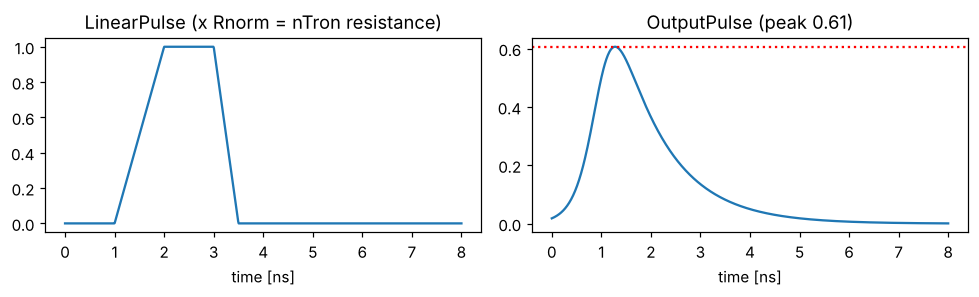

In [4]:
# vs original: LinearPulse same maths (the script stores t-t0 in a temp variable delta_t);
#              OutputPulse identical.
def LinearPulse(t, t0=5.0e-9, width=0.5e-9, rise=1.0e-9, fall=0.5e-9):  # trapezoid, 0..1
  if (t-t0 < 0) or (t-t0 > width+fall+rise):
    return 0
  if ((t-t0) > 0) and ((t - t0) < rise):
    return (t-t0)/rise
  if (t-t0 > width+rise) and (t-t0 <= width+fall+rise):
    return ((t0+width+fall+rise)-t)/fall
  else:
    return 1

def OutputPulse(t, t0=1e-9, tau=1.0e-9, mu0=0.2e-9):  # sigmoid rise at t0, exp decay with tau
  return (1.0 - 1.0/(math.exp((t - t0)/mu0) + 1.0))*math.exp(- ((t - t0)/tau))

ts = np.linspace(0, 8e-9, 800)
fig, axs = plt.subplots(1, 2, figsize=(9, 2.8))
axs[0].plot(ts*1e9, [LinearPulse(t, t0=1e-9, width=1e-9) for t in ts])
axs[0].set(title="LinearPulse (x Rnorm = nTron resistance)", xlabel="time [ns]")
op = [OutputPulse(t, t0=1e-9) for t in ts]
axs[1].plot(ts*1e9, op)
axs[1].axhline(max(op), ls=":", color="r")
axs[1].set(title=f"OutputPulse (peak {max(op):.2f})", xlabel="time [ns]")
plt.tight_layout(); plt.show()

## 3. The wiring: `delay` → `connectivity` → `input_connections`

**Rows are senders, columns are receivers.** A nonzero entry is a connection with that delay in ns;
0 means no connection. Rows/columns 0–1 are the two sensors (i1, i2), 2–7 are transponders t1–t6.

In [5]:
# vs original: `delay` is CHANGED (see below); names, connectivity, input_delays, input_connections same
#              as the script's logic. Row = sender, column = receiver.
names = ['i1', 'i2', 't1', 't2', 't3', 't4', 't5', 't6']
##                       to: i1  i2  t1  t2  t3  t4  t5  t6    from:
# vs original: the script's matrix is purely feedforward (t1->t3, t2->t3, t3->t4; t4-t6 send nothing).
# Here: t1,t2,t3 are mutually recurrent, t3->t4 is the one feedforward link, t4,t5,t6 are recurrent.
delay = 1.0e-9* np.array([[  0 , 0 , 5 , 0 , 0 , 0 , 9 , 0],   # i1
                          [  0 , 0 , 0 , 5 , 0 , 0 , 0 , 5],   # i2
                          [  0 , 0 , 0 , 5 , 5 , 0 , 0 , 0],   # t1  -> t2, t3
                          [  0 , 0 , 5 , 0 , 5 , 0 , 0 , 0],   # t2  -> t1, t3
                          [  0 , 0 , 5 , 5 , 0 , 5 , 0 , 0],   # t3  -> t1, t2 ; t4 (only feedforward link)
                          [  0 , 0 , 0 , 0 , 0 , 0 , 5 , 5],   # t4  -> t5, t6
                          [  0 , 0 , 0 , 0 , 0 , 5 , 0 , 5],   # t5  -> t4, t6
                          [  0 , 0 , 0 , 0 , 0 , 5 , 5 , 0],   # t6  -> t4, t5
                          ])
N_transponders = len(delay)
connectivity = np.minimum(1, np.ceil(delay))   # 1 where there is a connection, else 0
print("connectivity (rows = from, cols = to):\n", connectivity.astype(int))

connectivity (rows = from, cols = to):
 [[0 0 1 0 0 0 1 0]
 [0 0 0 1 0 0 0 1]
 [0 0 0 1 1 0 0 0]
 [0 0 1 0 1 0 0 0]
 [0 0 1 1 0 1 0 0]
 [0 0 0 0 0 0 1 1]
 [0 0 0 0 0 1 0 1]
 [0 0 0 0 0 1 1 0]]


The simulation needs the opposite view — for each receiver, who sends to it — so the script
transposes. `input_delays[i][j]` is the delay of the j → i link.

The **row sums** of `connectivity` are also important: a node's output is split evenly between
everything it feeds, so a node that feeds 3 others sends each one a smaller pulse than a node
that feeds 2.

In [6]:
input_delays = delay.T
input_connections = [[] for _ in range(N_transponders)]
for i, arow in enumerate(connectivity.T):
  for j, acol in enumerate(arow):
    if acol == 1:
      input_connections[i].append(j)

for i in range(N_transponders):
  fan_out = int(np.sum(connectivity[i]))
  print(f"{names[i]}: receives from {[names[j] for j in input_connections[i]]!s:22}  "
        f"sends to {fan_out} node(s)")

i1: receives from []                      sends to 2 node(s)
i2: receives from []                      sends to 2 node(s)
t1: receives from ['i1', 't2', 't3']      sends to 2 node(s)
t2: receives from ['i2', 't1', 't3']      sends to 2 node(s)
t3: receives from ['t1', 't2']            sends to 3 node(s)
t4: receives from ['t3', 't5', 't6']      sends to 2 node(s)
t5: receives from ['i1', 't4', 't6']      sends to 2 node(s)
t6: receives from ['i2', 't4', 't5']      sends to 2 node(s)


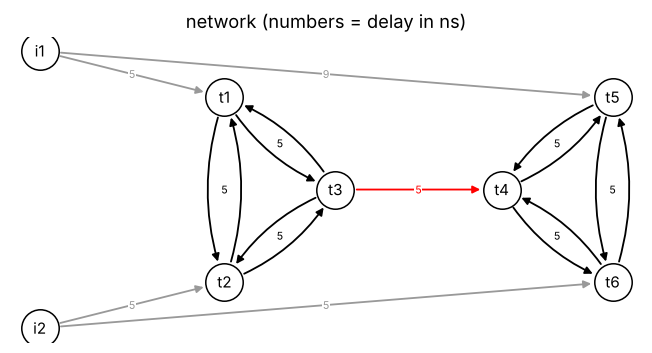

In [7]:
# Draw the network. Grey arrows = sensor inputs, black = recurrent, red = the feedforward link.
pos = {0: (0, 1.5), 1: (0, -1.5), 2: (2, 1), 3: (2, -1), 4: (3.2, 0),
       5: (5, 0), 6: (6.2, 1), 7: (6.2, -1)}
fig, ax = plt.subplots(figsize=(9, 3.6))
for j in range(N_transponders):
  for i in range(N_transponders):
    if connectivity[j, i]:
      bidir = connectivity[i, j] == 1
      col = "0.6" if j < 2 else ("r" if (j, i) == (4, 5) else "k")
      ax.annotate("", xy=pos[i], xytext=pos[j],
                  arrowprops=dict(arrowstyle="-|>", color=col, lw=1.2, shrinkA=14, shrinkB=14,
                                  connectionstyle=f"arc3,rad={0.18 if bidir else 0.0}"))
      mx, my = (pos[i][0]+pos[j][0])/2, (pos[i][1]+pos[j][1])/2
      ax.text(mx, my, f"{delay[j, i]*1e9:.0f}", fontsize=7, color=col, ha="center", va="center",
              bbox=dict(fc="white", ec="none", pad=0.5))
for n, (x, y) in pos.items():
  ax.scatter(x, y, s=600, c="w", edgecolors="k", zorder=3)
  ax.text(x, y, names[n], ha="center", va="center", zorder=4)
ax.set_title("network (numbers = delay in ns)"); ax.axis("off"); ax.set_aspect("equal")
plt.show()

## 4. One transponder on its own (not in the script)

Each transponder has two state variables, which `solve_ivp` integrates:

* **`i_nw`** — current through the *input* nTron channel. It sits at the input bias `Ib1`.
* **`i_loop`** — current in the transponder loop, which drives the *output* nTron.

How the model's names map onto the single-transponder schematic (`single_transponder_simple.pdf`):

| schematic | model | notes |
|---|---|---|
| pulser1 (U1), pulser2 (U4) | sensors i1, i2 (`sensor_pulses`) | |
| ① input loop: R28/L18, R29/L19 | gate current, `amp * OutputPulse` | pulse shape fixed by `OutputPulse`, not by R28/L18 |
| bias3 in, `I_b1` | `Ib1`, `transponder_bias1` | 150 µA in LTspice, 12 µA here |
| U3 input nTron (Q1): `L_nw1`, `R_nw1(t)` | `Lnw`, `Rnw` = `Rnorm * LinearPulse`, threshold `Inw1_sw` | current through it = `i_nw` |
| ② shunt: L1 (5 nH), R3 (3 Ω) = `L_s1`, `R_s1` | `Ls1` = 5 nH, `Rs1` = 2 Ω | R3 differs |
| ③ storage loop: Lb1 (~148 nH) = `L_T`, R2 (4 Ω) = `R_T` | `LT` = 150 nH, `RT0` = 3 Ω | R2 differs; current = `i_loop` (`I_loop`) |
| bias4 in, `I_b2` | `Ib2`, `transponder_bias2` | 160 µA in LTspice, 19 µA here |
| U2 output nTron (Q2): `L_nw2`, `R_nw2(t)` | threshold `Inw2_sw`; switching added to R2 as `RT = RT0 + Rnorm*LinearPulse` | no state variable, `L_nw2` not modelled |
| ④ output loop: L2 (5 nH), R1 (3 Ω) = `L_out`, `R_s2` | `split` (`transponder_current_divider`) | not modelled as parts; `split` is the share that reaches the next gates |

Switching is a threshold rule layered on top of the circuit equations:

1. **Input click:** when `i_nw + gate current > I1sw`, the input channel goes normal
   (`Rnw = Rnorm * LinearPulse`). That diverts `i_nw` into the loop: `i_nw` drops to ~0 and
   `i_loop` rises.
2. **Output click (the spike):** when `i_loop + Ib2 > I2sw`, the output nTron switches
   (`RT = RT0 + Rnorm * LinearPulse`), dumping the loop current. This is the event that sends a
   pulse to downstream nodes.

`y1` and `y2` below are the circuit equations from the script's `RHS`, copied unchanged.

Below, one node (input bias 12 µA) gets a single input pulse at 5 ns. A pulse peaking at
2.9 µA — what one spike delivers when the sender feeds 2 nodes (0.61 × 19 × 0.5 / 2) — gives
12 + 2.9 > 14 and the node fires; a 1.5 µA pulse doesn't.

pulse 2.9 uA: input click at 4.9 ns, spike at 11.9 ns


pulse 1.5 uA: input click at None ns, spike at None ns


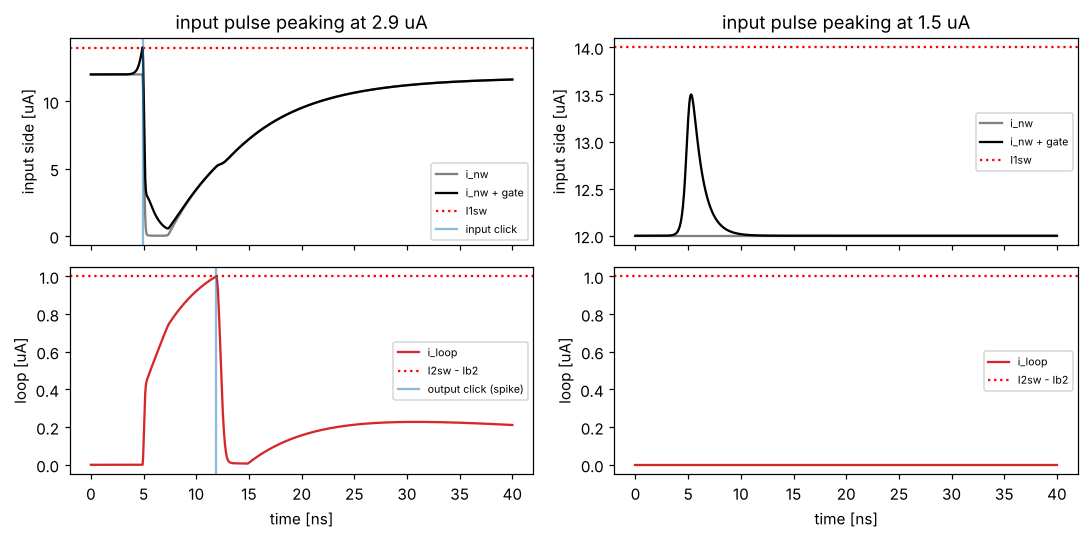

In [8]:
# vs original: NEW section (not in the script). A stand-alone one-transponder copy of the rules,
#              firing each nTron at most once. y1/y2 are copied from RHS.
PEAK = 0.6063   # max of OutputPulse (section 2)

def single_node(pulse_peak, Ib1_n=12e-6, Ib2_n=19e-6, t_pulse=5e-9, t_end=40e-9):
  pulse_amp = pulse_peak/PEAK   # nominal amplitude that gives this peak
  st = dict(in_state=0, out_state=0, t_in=None, t_out=None)
  log = dict(t=[], gate=[], Rnw=[], RT=[])
  def rhs(t, x):
    inw, iloop = x
    gate = pulse_amp * OutputPulse(t, t0=t_pulse) if t >= t_pulse - 2e-9 else 0.0   # loop 1 (pulser -> U3 gate)
    # output nTron (U2): same rule as RHS
    if st["out_state"] == 1:
      RT = RT0 + Rnorm*LinearPulse(t, t0=st["t_out"], width=2.0e-9)
      if t - st["t_out"] > ref_period: st["out_state"] = 0
    else:
      RT = RT0
      if iloop + Ib2_n > Inw2_sw and st["t_out"] is None:
        st["out_state"], st["t_out"] = 1, t
    # input nTron (U3): same rule as RHS
    Rnw = 0.0
    if st["in_state"] == 0 and inw + gate > Inw1_sw and st["t_in"] is None:
      st["in_state"], st["t_in"] = 1, t
    if st["in_state"] == 1:
      if t - st["t_in"] > ref_period: st["in_state"] = 0
      else: Rnw = Rnorm*LinearPulse(t, t0=st["t_in"], width=1.0e-9)
    i1 = Ib1_n
    y1 = (-inw*Ls1*Rnw - i1*LT*Rs1 + iloop*LT*Rs1 + inw*LT*(Rnw + Rs1) + iloop*Ls1*RT)/(Lnw*(Ls1 - LT) - Ls1*LT)
    y2 = (-inw*Ls1*Rnw - i1*Lnw*Rs1 + iloop*Lnw*Rs1 + inw*Lnw*Rs1 + iloop*Lnw*RT + iloop*Ls1*RT)/(Lnw*(Ls1 - LT) - Ls1*LT)
    return [y1, y2]
  tt = np.linspace(0, t_end, 800)
  sol = solve_ivp(rhs, (0, t_end), [Ib1_n, 0.0], t_eval=tt, max_step=1e-12)
  gate = np.array([pulse_amp*OutputPulse(t, t0=t_pulse) for t in tt])
  return sol, gate, st

fig, axs = plt.subplots(2, 2, figsize=(10, 5), sharex=True)
for col, amp in enumerate([2.9e-6, 1.5e-6]):
  sol, gate, st = single_node(amp)
  tn = sol.t*1e9
  ax = axs[0, col]
  ax.plot(tn, sol.y[0]*1e6, color="0.5", label="i_nw")
  ax.plot(tn, (sol.y[0]+gate)*1e6, "k", label="i_nw + gate")
  ax.axhline(Inw1_sw*1e6, color="r", ls=":", label="I1sw")
  ax.set(title=f"input pulse peaking at {amp*1e6:.1f} uA", ylabel="input side [uA]")
  ax = axs[1, col]
  ax.plot(tn, sol.y[1]*1e6, "tab:red", label="i_loop")
  ax.axhline((Inw2_sw - 19e-6)*1e6, color="r", ls=":", label="I2sw - Ib2")
  ax.set(xlabel="time [ns]", ylabel="loop [uA]")
  for a, tclick, lab in [(axs[0, col], st["t_in"], "input click"), (axs[1, col], st["t_out"], "output click (spike)")]:
    if tclick: a.axvline(tclick*1e9, color="tab:blue", alpha=.5, label=lab)
  axs[0, col].legend(fontsize=7); axs[1, col].legend(fontsize=7)
  print(f"pulse {amp*1e6:.1f} uA: input click at {st['t_in'] and round(st['t_in']*1e9, 2)} ns, "
        f"spike at {st['t_out'] and round(st['t_out']*1e9, 2)} ns")
plt.tight_layout(); plt.show()

What to notice: the spike comes about **7 ns after** the input click — the time the loop current
takes to climb to `I2sw - Ib2` (1 µA here). That lag depends on the biases; in the network run
below, t3 (input bias 11.2 µA) takes ~10 ns. And after clicking, `i_nw` takes ~20 ns to recover to
its bias — during that time the node needs a much bigger input to click again.

(This single-node version fires each nTron at most once, to keep it simple; the network `RHS`
below lets them re-fire.)

## 5. The full network

### 5a. `reset_state()` — run this before every solve

`RHS` keeps its bookkeeping in global variables and **changes them while the solver runs**: it
appends to `input_click_times` / `output_click_times`, flips `input_states` / `output_states`, and
removes sensor clicks from `sensor_pulses` once they have fired. If you solve twice without
resetting, the second run starts with the first run's spikes already recorded and the sensors
already used up — no error, just wrong results. `reset_state()` rebuilds all of it from the
parameters, which is what running the script fresh does.

In [9]:
# vs original: the script runs this block once at import (top level, using args.*). Here it is a
#              function so the network can be re-run. Same initial values; bias overrides come from
#              ib1_overrides / ib2_overrides dicts instead of args.ib1 / args.ib2.
def reset_state():
  global transponder_bias1, transponder_bias2, input_states, output_states
  global input_click_times, output_click_times, sensor_pulses
  global transponder_Rnw_input, transponder_RT_loop, transponder_input_gate_current
  global transponder_source_current, transponder_initial_state

  transponder_bias1 = Ib1*np.ones(N_transponders)   # I_b1 (bias3) of every node
  transponder_bias2 = Ib2*np.ones(N_transponders)   # I_b2 (bias4) of every node
  for n, v in ib1_overrides.items(): transponder_bias1[int(n)] = v*1.0e-6
  for n, v in ib2_overrides.items(): transponder_bias2[int(n)] = v*1.0e-6

  # state: 0 = superconducting (ready), 1 = clicked
  input_states  = np.zeros(N_transponders)
  output_states = np.zeros(N_transponders)
  input_click_times  = [[] for _ in range(N_transponders)]
  output_click_times = [[] for _ in range(N_transponders)]
  sensor_pulses = [[1.0e-9], [1.0e-9 + dt]]   # i1 clicks at 1 ns, i2 at 1 ns + dt
                                              #   schematic: pulser1 (U1) and pulser2 (U4)

  transponder_Rnw_input = np.zeros(N_transponders)   # U3 channel resistance "R_nw1(t)": 0 = superconducting
  transponder_RT_loop   = RT0*np.ones(N_transponders)   # loop-3 resistance "R_T(t)": R2, plus U2 while it switches
  transponder_input_gate_current = np.zeros(N_transponders)
  transponder_source_current     = np.zeros(N_transponders)

  # solver state vector is interleaved: [i_nw(0), i_loop(0), i_nw(1), i_loop(1), ...]
  transponder_initial_state = np.empty(2*N_transponders)
  transponder_initial_state[0::2] = transponder_bias1   # i_nw starts at its bias
  transponder_initial_state[1::2] = 0.0                 # no loop current yet

reset_state()
print("input biases  [uA]:", transponder_bias1*1e6)
print("output biases [uA]:", transponder_bias2*1e6)
print("initial state vector [uA]:", np.round(transponder_initial_state*1e6, 2))

input biases  [uA]: [12.  12.  13.  12.  11.2 12.  12.  12. ]
output biases [uA]: [19. 19. 19. 19. 19. 19. 19. 19.]
initial state vector [uA]: [12.   0.  12.   0.  13.   0.  12.   0.  11.2  0.  12.   0.  12.   0.
 12.   0. ]


### 5b. `RHS` — copied from the script (only its progress prints were trimmed)

`solve_ivp` calls this at every (sub)step with the current time `t` and state `x`. In order it:

1. fires the sensors at their scheduled times (they are just forced output clicks);
2. for each node's **output** nTron: sets `RT` from the last spike, or checks
   `i_loop + Ib2 > I2sw` and records a spike;
3. for each node's **input** nTron: sums the pulses from every upstream spike (the *gate
   current*), checks `i_nw + gate > I1sw` and records an input click, and sets `Rnw`;
4. returns `d(i_nw)/dt` and `d(i_loop)/dt` for every node from the circuit equations.

The gate current from step 3 is used and then discarded — it is not part of the solution. That
is why section 6 rebuilds it.

In [10]:
# vs original: identical logic. Removed: debug prints; `click_delay` temp variable (RHS step 3 now inlines it).
#              Added: comments only.
def RHS(t, x):
  nw_currents   = x[::2]    # current through U3's channel (drain -> source), loop 2
  loop_currents = x[1::2]   # "I_loop": current around the storage loop 3 (Lb1, R2) into U2's gate
  eps = 1.0e-11

  # 1. sensor clicks  (schematic: pulser1 / pulser2)
  for n, clicks in enumerate(sensor_pulses):
    for i_click, sensor_click_t in enumerate(clicks):
      if abs(t - sensor_click_t) <= eps:
        print(f"sensor {names[n]} clicks at {t*1e9:.2f} ns")
        output_states[n] = 1
        output_click_times[n].append(t)
        sensor_pulses[n].pop(i_click)

  # 2. output nTrons  (schematic: U2). U2 itself has no state variable here: when it switches, its
  #    resistance is added onto R2 as RT, which dumps I_loop. L_nw2, L2 and R1 are not modelled.
  for i_out, output_state in enumerate(output_states):
    if output_states[i_out] == 1:
      tlast = output_click_times[i_out][len(output_click_times[i_out])-1]
      transponder_RT_loop[i_out] = RT0 + Rnorm*LinearPulse(t, t0=tlast, width=2.0e-9)   # R2 + U2 switched
      if t - tlast > ref_period:
        output_states[i_out] = 0
    if output_states[i_out] == 0:
      transponder_RT_loop[i_out] = RT0
      if loop_currents[i_out] + transponder_bias2[i_out] > Inw2_sw:   # I_loop (into U2 gate) + I_b2 > U2 threshold
        output_states[i_out] = 1
        output_click_times[i_out].append(t)

  # 3. input nTrons  (schematic: U3). The gate current is loop 1: in the schematic it comes from the
  #    pulsers through R28/L18 and R29/L19; here its shape is fixed by OutputPulse instead.
  for i_in, input_state in enumerate(input_states):
    if input_states[i_in] == 0:
      transponder_Rnw_input[i_in] = 0
      ntron_gate_current = 0
      transponder_input_gate_current[i_in] = 0
      for j_in in input_connections[i_in]:
        n_split = np.sum(connectivity[j_in])
        b2  = transponder_bias2[j_in]
        amp = b2*transponder_current_divider/n_split   # sender's I_b2 x split, shared between its targets
        for click_t in output_click_times[j_in]:
          click_arrival = click_t + input_delays[i_in][j_in]
          ntron_gate_current += amp*OutputPulse(t, t0=click_arrival)   # loop 1: current into U3's gate
      transponder_source_current[i_in]     = nw_currents[i_in] + ntron_gate_current
      transponder_input_gate_current[i_in] = ntron_gate_current
      if nw_currents[i_in] + ntron_gate_current > Inw1_sw:   # U3 channel + gate current > U3 threshold
        input_states[i_in] = 1
        input_click_times[i_in].append(t)
    if input_states[i_in] == 1:
      latest_input_click = input_click_times[i_in][len(input_click_times[i_in])-1]
      if t - latest_input_click > ref_period:
        input_states[i_in] = 0
      else:
        transponder_Rnw_input[i_in] = Rnorm*LinearPulse(t, t0=latest_input_click, width=1.0e-9)   # U3 "R_nw1(t)"

  # 4. circuit equations: I_b1 splits between three parallel branches to ground --
  #    U3 (Lnw, Rnw), shunt L1/R3 (Ls1, Rs1) and storage loop Lb1/R2 (LT, RT).
  #    y1 = d(i_nw)/dt, y2 = d(I_loop)/dt. NOTE: these give the right steady-state split, but the
  #    Lnw*Ls1 term in the denominator has the opposite sign from the circuit as drawn
  #    (drawn: Lnw*Ls1 + Lnw*LT + Ls1*LT); time constants differ by ~5%. Worth checking with Whit.
  y = []
  for i_node, loop_cur in enumerate(loop_currents):
    i1  = transponder_bias1[i_node]   # I_b1 (bias3)
    inw = nw_currents[i_node]
    iloop = loop_cur
    Rnw = transponder_Rnw_input[i_node]   # U3 "R_nw1(t)"
    RT  = transponder_RT_loop[i_node]     # "R_T(t)" = R2 (+ U2 while switching)
    y1 = (-inw*Ls1*Rnw - i1*LT*Rs1 + iloop*LT*Rs1 + inw*LT*(Rnw + Rs1) + iloop*Ls1*RT)/(Lnw*(Ls1 - LT) - Ls1*LT)
    y2 = (-inw*Ls1*Rnw - i1*Lnw*Rs1 + iloop*Lnw*Rs1 + inw*Lnw*Rs1 + iloop*Lnw*RT + iloop*Ls1*RT)/(Lnw*(Ls1 - LT) - Ls1*LT)
    y.append(y1)
    y.append(y2)
  return y

### 5c. Solve (about a minute)

`max_step = 1 ps` is what makes this slow; it is needed so the solver doesn't step over the
sub-nanosecond switching events.

In [11]:
# vs original: the script calls solve_ivp inside main() with 100e-9 written in; here it is a function
#              using T_END, and calls reset_state() first.
def solve_network():
  reset_state()
  t_pts = np.linspace(0, T_END, num=1000)
  return solve_ivp(RHS, (0, T_END), transponder_initial_state, t_eval=t_pts, max_step=1.0e-12)

solution = solve_network()
t, tns = solution.t, solution.t/1.0e-9
print("solver status:", solution.status, "| state array shape:", solution.y.shape)
print("\noutput (spike) click times [ns]:")
for n in range(N_transponders):
  print(f"  {names[n]}: {np.round(np.array(output_click_times[n])/1.0e-9, 2)}")
print("\ninput (gate) click times [ns]:")
for n in range(2, N_transponders):
  print(f"  {names[n]}: {np.round(np.array(input_click_times[n])/1.0e-9, 2)}")

sensor i1 clicks at 0.99 ns


sensor i2 clicks at 35.99 ns


solver status: 0 | state array shape: (16, 1000)

output (spike) click times [ns]:
  i1: [0.99]
  i2: [35.99]
  t1: [10.75 29.69 50.77]
  t2: [22.63 44.52]
  t3: [26.25]
  t4: [28.77 54.02]
  t5: [16.87 37.03 61.43]
  t6: [28.77 45.62 69.  ]

input (gate) click times [ns]:
  t1: [ 5.64 27.58 49.5 ]
  t2: [15.65 41.13]
  t3: [15.91]
  t4: [21.77 50.68]
  t5: [ 9.89 33.55 59.22]
  t6: [21.77 41.73 66.68]


### 5d. The script's original trace plot

`solution.y` is 16 rows: row `2n` is `i_nw` of node n, row `2n+1` is `i_loop`. The script's
6-panel figure plots rows 4–9, i.e. **t1, t2, t3** — its labels "gate 2/3/4" are row indices,
and "gate" there is the channel current `i_nw`, not the gate current.

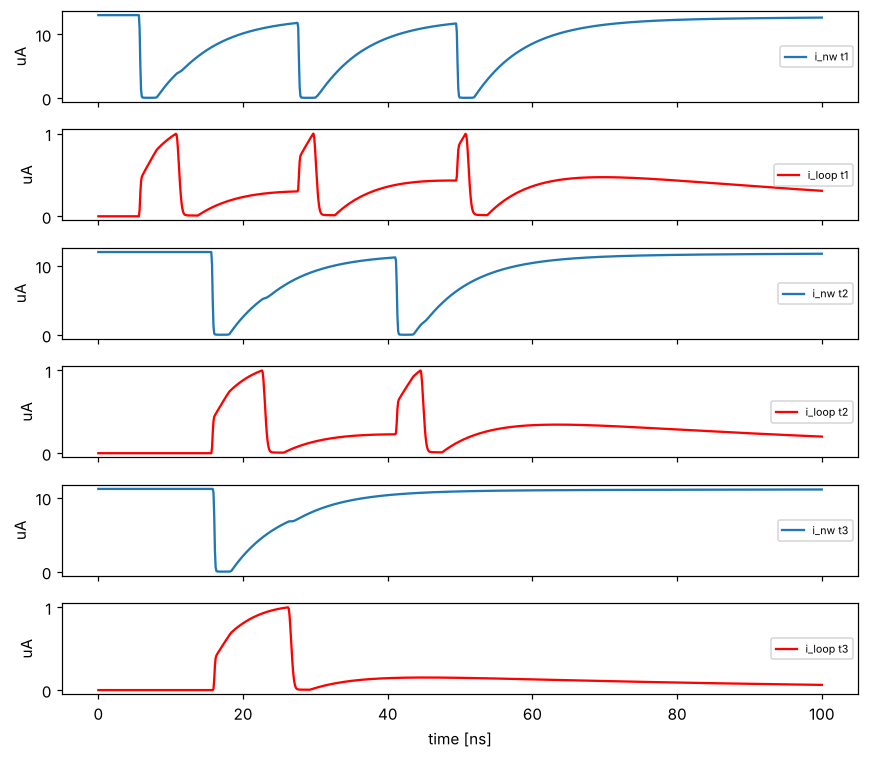

In [12]:
fig, axs = plt.subplots(6, sharex=True, figsize=(8, 7))
for k, n in enumerate([2, 3, 4]):
  axs[2*k].plot(tns, solution.y[2*n]/1e-6, label=f"i_nw {names[n]}")
  axs[2*k+1].plot(tns, solution.y[2*n+1]/1e-6, "r", label=f"i_loop {names[n]}")
for ax in axs:
  ax.legend(loc="right", fontsize=7); ax.set_ylabel("uA")
axs[-1].set_xlabel("time [ns]")
plt.tight_layout(); plt.show()

## 6. Rebuilding the gate current

Same formula as step 3 of `RHS`, applied after the run to the recorded spike times: every spike
from j reaches i after the j → i delay and adds `amp * OutputPulse`, where
`amp = Ib2(j) * split / (number of nodes j feeds)`. `gate_parts[i][j]` keeps each upstream node's
contribution separately; `gate_current[i]` is their sum.

In [13]:
# vs original: NEW (post-processing added to the script after the run; not in main). Same recipe
#              as RHS step 3 (RHS step 3), applied to the recorded click times.
gate_parts = [dict() for _ in range(N_transponders)]
gate_current = np.zeros((N_transponders, len(t)))
for i_in in range(N_transponders):
  for j_in in input_connections[i_in]:
    amp  = transponder_bias2[j_in]*transponder_current_divider/np.sum(connectivity[j_in])
    part = np.zeros(len(t))
    for click_t in output_click_times[j_in]:
      arrival = click_t + input_delays[i_in][j_in]
      part += np.array([amp*OutputPulse(tk, t0=arrival) if tk >= click_t else 0.0 for tk in t])
    gate_parts[i_in][j_in] = part
    gate_current[i_in] += part

Pick a node and see exactly which spikes land on it, when, and how big. Change `node` to inspect
another one (0 = i1 … 7 = t6).

In [14]:
# vs original: NEW (notebook only). `node` picks which transponder to inspect.
node = 4   # t3
need = (Inw1_sw - transponder_bias1[node])*1e6
print(f"{names[node]}: input bias {transponder_bias1[node]*1e6:.1f} uA -> needs {need:.2f} uA of gate current to click\n")
print(f"{'from':>5} {'spike [ns]':>11} {'arrives [ns]':>13} {'peak [uA]':>10}")
for j_in in input_connections[node]:
  amp = transponder_bias2[j_in]*transponder_current_divider/np.sum(connectivity[j_in])
  for click_t in output_click_times[j_in]:
    arr = click_t + input_delays[node][j_in]
    print(f"{names[j_in]:>5} {click_t*1e9:11.2f} {arr*1e9:13.2f} {0.606*amp*1e6:10.2f}")
print(f"\nlargest summed gate current on {names[node]}: {gate_current[node].max()*1e6:.2f} uA")

t3: input bias 11.2 uA -> needs 2.80 uA of gate current to click

 from  spike [ns]  arrives [ns]  peak [uA]
   t1       10.75         15.75       2.88
   t1       29.69         34.69       2.88
   t1       50.77         55.77       2.88
   t2       22.63         27.63       2.88
   t2       44.52         49.52       2.88

largest summed gate current on t3: 2.89 uA


## 7. The three plots

### 7a. Spike raster
Black ticks = output clicks (spikes); red triangles = input (gate) clicks. Dashed lines separate
sensors | t1–t3 | t4–t6.

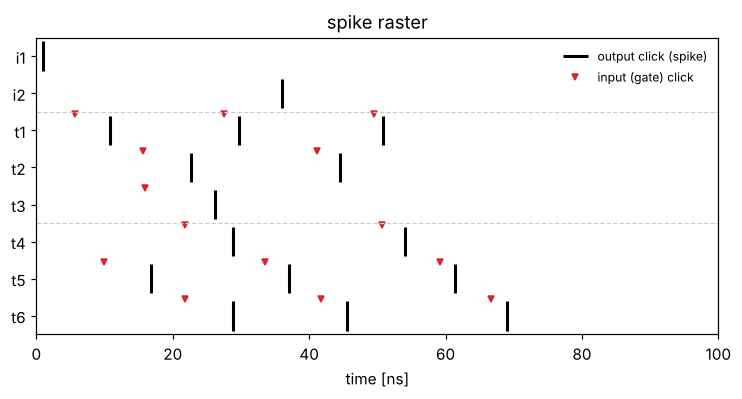

In [15]:
# vs original: NEW (the script has an equivalent raster added after main; not in main).
fig, ax = plt.subplots(figsize=(8, 3.5))
for n in range(N_transponders):
  ax.vlines(np.array(output_click_times[n])/1.0e-9, n-0.4, n+0.4, color='k', lw=2,
            label='output click (spike)' if n == 0 else None)
  if input_click_times[n]:
    ax.plot(np.array(input_click_times[n])/1.0e-9, [n-0.45]*len(input_click_times[n]), 'v',
            color='tab:red', ms=4, label='input (gate) click' if not any(input_click_times[:n]) else None)
for y in (1.5, 4.5):
  ax.axhline(y, color='0.8', ls='--', lw=0.8)
ax.set_yticks(range(N_transponders), names)
ax.set_ylim(N_transponders-0.5, -0.5)
ax.set(xlim=(0, tns[-1]), xlabel='time [ns]', title='spike raster')
ax.legend(loc='upper right', fontsize=8, frameon=False)
plt.show()

### 7b. Gate-current trace for one node
Top: each upstream contribution (dashed) and their sum (black) against the gate current needed to
click. Bottom: what the threshold rule actually compares — `i_nw + gate` against `I1sw`.
Uses `node` from section 6.

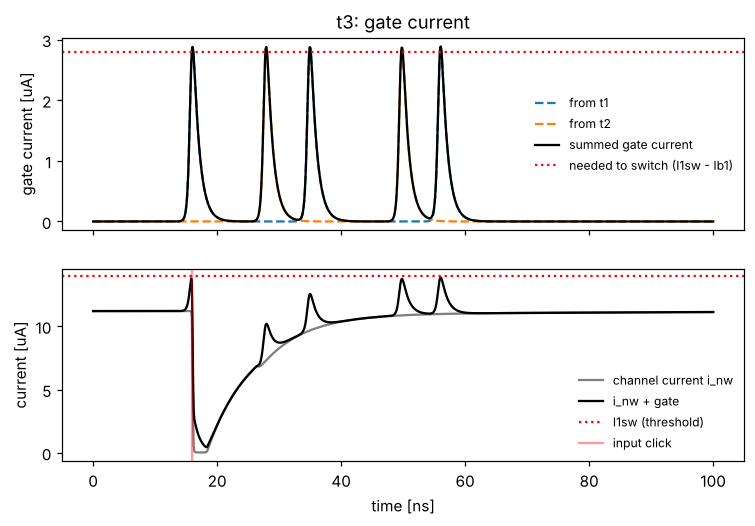

In [16]:
# vs original: NEW (the script has an equivalent gate-trace plot added after main; not in main).
n = node
inw = solution.y[2*n]
fig, axs2 = plt.subplots(2, sharex=True, figsize=(8, 5))
for j_in, part in gate_parts[n].items():
  axs2[0].plot(tns, part/1.0e-6, '--', label=f'from {names[j_in]}')
axs2[0].plot(tns, gate_current[n]/1.0e-6, 'k', lw=1.5, label='summed gate current')
axs2[0].axhline((Inw1_sw - transponder_bias1[n])/1.0e-6, color='r', ls=':', label='needed to switch (I1sw - Ib1)')
axs2[0].set(ylabel='gate current [uA]', title=f'{names[n]}: gate current')
axs2[0].legend(fontsize=8, frameon=False)
axs2[1].plot(tns, inw/1.0e-6, color='0.5', label='channel current i_nw')
axs2[1].plot(tns, (inw + gate_current[n])/1.0e-6, 'k', label='i_nw + gate')
axs2[1].axhline(Inw1_sw/1.0e-6, color='r', ls=':', label='I1sw (threshold)')
for k, tc in enumerate(input_click_times[n]):
  axs2[1].axvline(tc/1.0e-9, color='r', alpha=0.4, label='input click' if k == 0 else None)
axs2[1].set(xlabel='time [ns]', ylabel='current [uA]')
axs2[1].legend(fontsize=8, frameon=False)
plt.show()

### 7c. Gradient raster
Grey = gate current (white = none, black = the largest gate current in the run). Each row goes
white for `ref_period` after an input click. Solid red = spike, dotted red = input click.

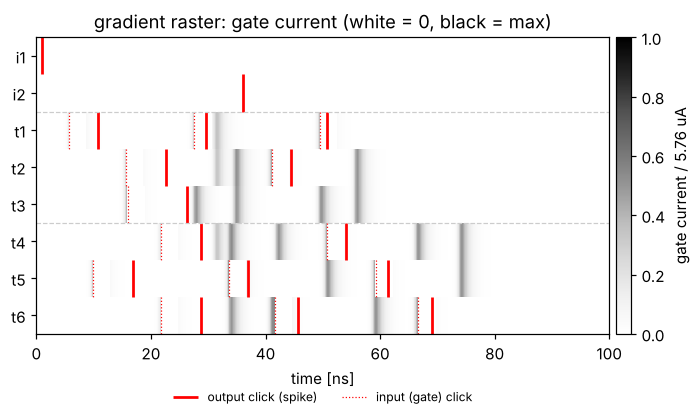

In [17]:
# vs original: NEW (added to the script after main; the original has only the 6-panel trace plot).
def gradient_raster(ax, gate_current, input_click_times, output_click_times, title=None):
  gmax  = gate_current.max() if gate_current.max() > 0 else 1.0
  shade = gate_current/gmax
  for n in range(N_transponders):
    for tc in input_click_times[n]:
      shade[n][(t > tc) & (t <= tc + ref_period)] = 0
  im = ax.imshow(shade, aspect='auto', cmap='Greys', vmin=0, vmax=1, interpolation='nearest',
                 extent=(tns[0], tns[-1], N_transponders-0.5, -0.5))
  for n in range(N_transponders):
    ax.vlines(np.array(output_click_times[n])/1.0e-9, n-0.5, n+0.5, color='red', lw=1.8,
              label='output click (spike)' if n == 0 else None)
    ax.vlines(np.array(input_click_times[n])/1.0e-9, n-0.5, n+0.5, color='red', lw=0.8, ls=':',
              label='input (gate) click' if n == 2 else None)
  for y in (1.5, 4.5):
    ax.axhline(y, color='0.8', ls='--', lw=0.8)
  ax.set_yticks(range(N_transponders), names)
  ax.set(xlabel='time [ns]', title=title or 'gradient raster: gate current (white = 0, black = max)')
  return im, gmax

fig, ax = plt.subplots(figsize=(8, 3.5))
im, gmax = gradient_raster(ax, gate_current.copy(), input_click_times, output_click_times)
fig.colorbar(im, ax=ax, label=f'gate current / {gmax/1.0e-6:.2f} uA', pad=0.01)
ax.legend(loc='upper center', fontsize=8, frameon=False, ncol=2, bbox_to_anchor=(0.5, -0.15))
plt.show()

## 8. Bias sweep

Vary one node's input bias and keep everything else fixed. With the defaults: t3 (node 4) needs
~3.0 µA of gate current at 11 µA and a single pulse brings ~2.9 µA, so the interesting range is
around 11 µA. Each value is a full solve (~1 min). Edit `sweep_node` / `sweep_values` to taste.

In [18]:
# vs original: NEW (notebook only). Re-runs the whole network once per input bias value.
sweep_node   = 4
sweep_values = [10.5, 11.0, 11.2, 12.0]   # uA

saved_overrides = dict(ib1_overrides)
sweep = {}
for v in sweep_values:
  ib1_overrides[sweep_node] = v
  sol = solve_network()
  sweep[v] = dict(out=[list(c) for c in output_click_times], inp=[list(c) for c in input_click_times])
  print(f"{names[sweep_node]} Ib1 = {v:5.1f} uA -> spikes per node:",
        {names[k]: len(c) for k, c in enumerate(output_click_times) if k >= 2})
ib1_overrides.clear(); ib1_overrides.update(saved_overrides)   # put the parameter back

sensor i1 clicks at 0.99 ns


sensor i2 clicks at 35.99 ns


t3 Ib1 =  10.5 uA -> spikes per node: {'t1': 3, 't2': 2, 't3': 0, 't4': 2, 't5': 3, 't6': 3}


sensor i1 clicks at 0.99 ns


sensor i2 clicks at 35.99 ns


...

sensor i2 clicks at 35.99 ns


t3 Ib1 =  11.2 uA -> spikes per node: {'t1': 3, 't2': 2, 't3': 1, 't4': 2, 't5': 3, 't6': 3}


sensor i1 clicks at 0.99 ns


sensor i2 clicks at 35.99 ns


t3 Ib1 =  12.0 uA -> spikes per node: {'t1': 3, 't2': 2, 't3': 2, 't4': 2, 't5': 3, 't6': 3}


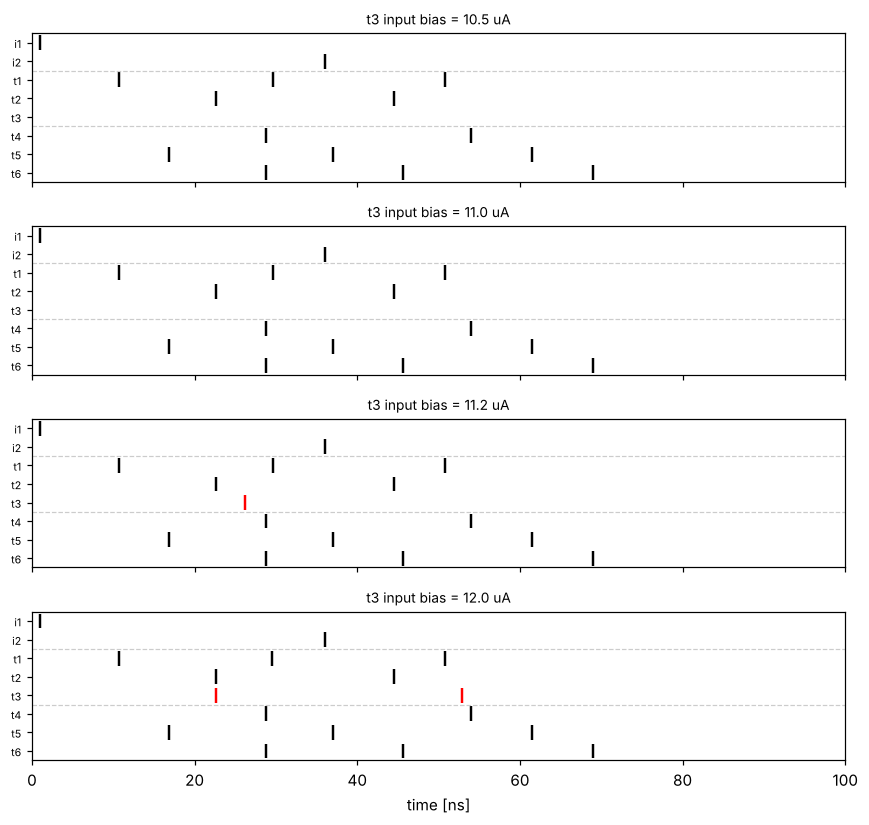

In [19]:
fig, axs = plt.subplots(len(sweep_values), sharex=True, figsize=(8, 1.9*len(sweep_values)))
for ax, v in zip(axs, sweep_values):
  for n in range(N_transponders):
    ax.vlines(np.array(sweep[v]["out"][n])/1e-9, n-0.4, n+0.4, color='r' if n == sweep_node else 'k', lw=1.6)
  for y in (1.5, 4.5):
    ax.axhline(y, color='0.8', ls='--', lw=0.8)
  ax.set_yticks(range(N_transponders), names, fontsize=7)
  ax.set_ylim(N_transponders-0.5, -0.5)
  ax.set_title(f"{names[sweep_node]} input bias = {v} uA", fontsize=9)
axs[-1].set(xlim=(0, T_END*1e9), xlabel="time [ns]")
plt.tight_layout(); plt.show()

With the default settings, t3 (red) goes from silent → one spike → two spikes as its bias rises,
but **t4–t6 are identical in every run**: t3's spike never makes t4 fire, because t4 already
clicked at ~22 ns — driven by t5 and t6, which get the sensor signals directly (i1 → t5,
i2 → t6) — and is still recovering when t3's pulse arrives. To
make the t3 → t4 link matter, set `delay[0, 6]` and `delay[1, 7]` to 0 in section 3.

**Before re-running anything above:** sections 5–7 use the global `solution` and click lists from
the last `solve_network()` call. The sweep overwrote the click lists, so re-run section 5c before
going back to sections 6–7.